#Evidencia 3: Econometría 1


Del 2 de Marzo al 11 de Marzo del 2026

#Objetivo

En este periódo tuvimos como objetivo validar la robustez y confiabilidad de los modelos de regresión lineal. Nuestro análisis se centró en mitigar la ineficiencia de la heterocedasticidad y el sesgo de la autocorrelación mediante técnicas de estimación avanzada (WLS, Cochrane-Orcutt y HAC), garantizando que las pruebas de hipótesis y la capacidad predictiva del modelo sean estadísticamente confiables en entornos de datos transversales y de series de tiempo.

### Índice de Contenidos

1. [Objetivo](#Objetivo)
2. [Código - Primera Parte](#Código---Primera-Parte)
3. [Primeros resultados con interpretación](#Primeros-resultados-con-interpretación)
4. [Código - Segunda Parte](#Código---Segunda-Parte)
5. [Resultados con interpretación 2.1](#Resultados-con-interpretación-2.1)
6. [Código - Tarea con interpretación](#Código---Tarea-con-interpretación)
7. [Aprendizajes clave](#Aprendizajes-clave)
8. [Aplicaciones en otros ámbitos](#Aplicaciones-en-otros-ámbitos)

#Código-Primera Parte

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.sandwich_covariance import cov_hac
from statsmodels.compat import lzip
sns.set(style="whitegrid")
np.random.seed(42)

In [ ]:
#Objetivos
objetivos = [
  "1) Estimar un modelo de MCO y obtener residuos.",
  "2) Detectar heteroscedasticidad (gráficos + test de Breusch–Pagan).",
  "3) Detectar autocorrelación (Durbin–Watson y Breusch–Godfrey).",
  "4) Corregir heteroscedasticidad (WLS y errores robustos White/Newey–West).",
  "5) Corregir autocorrelación (Cochrane–Orcutt) y verificar mejora."
]
for o in objetivos:
  print("✔", o)

✔ 1) Estimar un modelo de MCO y obtener residuos.
✔ 2) Detectar heteroscedasticidad (gráficos + test de Breusch–Pagan).
✔ 3) Detectar autocorrelación (Durbin–Watson y Breusch–Godfrey).
✔ 4) Corregir heteroscedasticidad (WLS y errores robustos White/Newey–West).
✔ 5) Corregir autocorrelación (Cochrane–Orcutt) y verificar mejora.


In [ ]:
# 2) Datos de corte transversal
# Escenario A: Corte transversal con heteroscedasticidad
n_A = 300
x_A = np.linspace(1, 10, n_A)
sigma_A = 0.3 * x_A                       # varianza crece con x (aquí esta la heterocedasticidad)
e_A = np.random.normal(scale=sigma_A)
y_A = 2 + 1.5 * x_A + e_A
df_A = pd.DataFrame({"y": y_A, "x": x_A, "sigma": sigma_A})
# Escenario B: Serie de tiempo con autocorrelación positiva
n_B = 200
t = np.arange(n_B)
x_B = np.linspace(0, 10, n_B) + np.random.normal(scale=0.4, size=n_B)
rho = 0.6
u = np.random.normal(scale=1.0, size=n_B)
e_B = np.zeros(n_B)
for i in range(1, n_B):
  e_B[i] = rho * e_B[i-1] + u[i]
y_B = 1.0 + 0.8 * x_B + e_B

df_B = pd.DataFrame({"t": t, "y": y_B, "x": x_B, "e": e_B})

In [ ]:
def fit_ols (y,X,add_constant=True):
  X_ = sm.add_constant(X) if add_constant else X
  model = sm.OLS(y,X_).fit()
  return model

  #Escenario A
model_A = fit_ols(df_A["y"],df_A[["x"]])
df_A["y_hat"] = model_A.fittedvalues
df_A["e"] = model_A.resid

  #Escenario B
model_B = fit_ols(df_B["y"],df_B[["x"]])
df_B["y_hat"] = model_B.fittedvalues
df_B["e"] = model_B.resid

print(model_A.summary())
print(model_B.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     1365.
Date:                Sun, 15 Mar 2026   Prob (F-statistic):          2.79e-113
Time:                        06:57:23   Log-Likelihood:                -611.05
No. Observations:                 300   AIC:                             1226.
Df Residuals:                     298   BIC:                             1234.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9100      0.251      7.612      0.0

#Primeros Resultados con interpretación

Escenario A (Corte Transversal): Vemos que tenemos un $R^2$ de 0.821, pero al analizar los errores , vemos que estos carecen de normalidad según el test de jaque-bera.

Escenario B (Serie de Tiempo):Aquí tenemos un $R^2$ de 0.819 y una relación entre $x$ y $y$ altamente significativa, a diferencia del escenario A , no tenemos problemas con los errores , pero el estadístico de Durbin-Watson arrojó un valor de 0.918, lo cual es una señal clara de autocorrelación positiva en los errores.

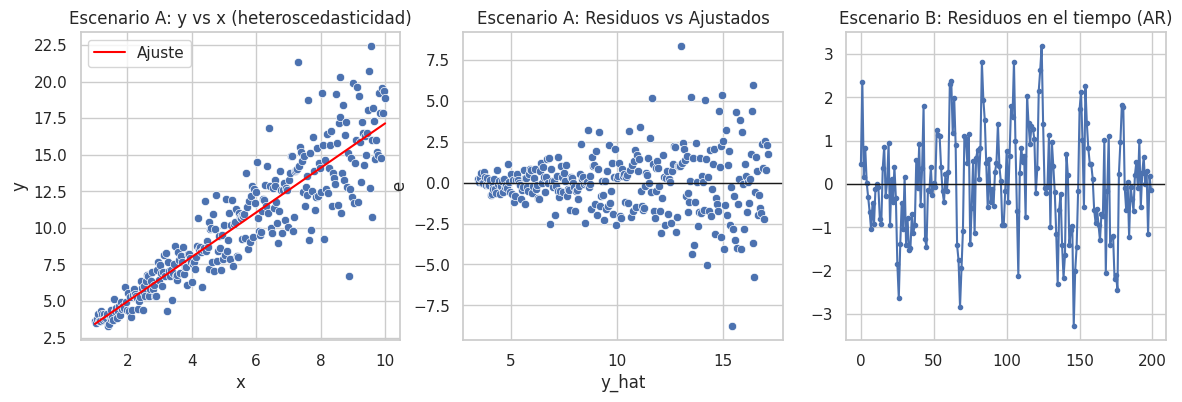

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.scatterplot(x="x", y="y", data=df_A, ax=axes[0])
axes[0].plot(df_A["x"], df_A["y_hat"], color="red", label="Ajuste")
axes[0].set_title("Escenario A: y vs x (heteroscedasticidad)")
axes[0].legend()

sns.scatterplot(x="y_hat", y="e", data=df_A, ax=axes[1])
axes[1].axhline(0, color="k", lw=1)
axes[1].set_title("Escenario A: Residuos vs Ajustados")

axes[2].plot(df_B["t"], df_B["e"], marker="o", ms=3, ls="-")
axes[2].axhline(0, color="k", lw=1)
axes[2].set_title("Escenario B: Residuos en el tiempo (AR)")
plt.show()

##Escenario A
En la primera gráfica vemos que los puntos que están más hacia la derecha, están mas separados de la línea roja, lo que nos dice que nuestros errores no son constantes, pues la incertidumbre de nuestro modelo aumenta conforme $x$ crece. En la segunda gráfica vemos que los residuos se distribuyen en forma de abanico , así que la varianza del error está correlacionada con el nivel de predicción.
##Escenario B
En esta gráfica notamos que los residuos tienden a seguir una trayectoría, lo que indica que hay una autocorrelación positiva , los errores no son independientes entre si ; lo que pasó anteriormente influye en el error actual

#Código-Segunda Parte

In [ ]:
# Heterocedasticidad del escenario A, utiliza
bp_test_A = het_breuschpagan(df_A['e'], sm.add_constant(df_A["x"]))
bp_labels = ['LM Stat', 'LM p-value', 'F stat', 'F p-value']
print('Breusch-Pagan (Escenario A):')
print(lzip(bp_labels, bp_test_A))

# Escenario B: Durbin-Watson y Breusch-Godfrey
# Prueba de Autocorrelación con DW para el escenario b
dw_B = durbin_watson(df_B['e'])
print('\nDurbin-Watson (Escenario B):', round(dw_B, 3))

#Breusch-Godfrey para AR(1)
bg_test_B = acorr_breusch_godfrey(model_B, nlags=1)
bg_labels = ['LM Stat', 'LM p-value', 'F stat', 'F p-value']
print('Breusch-Pagan (Escenario A):')
print(lzip(bg_labels, bg_test_B))

Breusch-Pagan (Escenario A):
[('LM Stat', np.float64(36.964971431296654)), ('LM p-value', np.float64(1.2027063530747355e-09)), ('F stat', np.float64(41.87868644897687)), ('F p-value', np.float64(3.984145688343634e-10))]

Durbin-Watson (Escenario B): 0.918
Breusch-Pagan (Escenario A):
[('LM Stat', np.float64(58.43167046201292)), ('LM p-value', np.float64(2.1047541196894747e-14)), ('F stat', 81.31083497688502), ('F p-value', 1.7175784573388075e-16)]


In [ ]:
# 5.1 WLS (pesos~1/Var(e|x))
weights_A = 1 / df_A["x"]**2
model_A_wls = sm.WLS(df_A["y"], sm.add_constant(df_A["x"]), weights=weights_A).fit()
#Se usa 1/x^2 por la forma en la que nosotros obtuvimos los datos ya que la varianzsa crece al ritmo de x
#5.2 OLS con erroress estándar robustos a heteroscedasticidad (White/HC0) #Esta varianza HC0 penaliza mediante que los errores sean muy grandes conforme la muestra se va haciendo grande
model_A_hc = model_A.get_robustcov_results(cov_type='HC0')
#Los estimadores se pueden usar aunque se tenga heterocedasticidad
#El peso que se necesita es 1/x^2 pero depende del gráfico
#Los errores se disminuyeron y se mejoraron los estimadores, pruebas e intervalos de confianza
#Varianza consistente con heteroscedasticidad no nos funciona en este caso
#Al mejorar la precision de los errores aumenta R^2 y se disminuye la distancia con R^2 adj
print("--- WLS Results ---")
print("Coeficientes:\n", model_A_wls.params.round(4))
print("P-valores:\n", model_A_wls.pvalues.round(4))
print("R-cuadrado:", round(model_A_wls.rsquared, 4))

print("\n--- HC0 Robust Errors Results ---")
print("Coeficientes:\n", model_A_hc.params.round(4))
print("P-valores:\n", model_A_hc.pvalues.round(4))
print("R-cuadrado:", round(model_A_hc.rsquared, 4))

--- WLS Results ---
Coeficientes:
 const    1.9151
x        1.5201
dtype: float64
P-valores:
 const    0.0
x        0.0
dtype: float64
R-cuadrado: 0.9031

--- HC0 Robust Errors Results ---
Coeficientes:
 [1.91   1.5231]
P-valores:
 [0. 0.]
R-cuadrado: 0.8208


#Resultados con interpretación 2.1

WLS: Como sabemos que la varianza del error crece proporcionalmente a $x$, el modelo asigna un peso a cada dato. Esto significa que el modelo le da mucha más importancia a los datos con valores bajos de $X$ que es donde hay más precisión y menos a los de la derecha, vemos que nuestra $R^2 = 0.903$ es más alta que en la del modelo OLS pues al corregir la varianza tenemos mejor precisión.

HC0: Nos ayuda a evitar declarar variables como "significativas" cuando en realidad el resultado se debe al desorden de la varianza.

**Notas**
* **WLS** asume una forma funcional para la varianza condicional
* **White/HC0** no requiere especificar la forma de la varianza; ajusta los errores estándar




In [ ]:
#6) Correcciones para autocorrelación
#=============================================
#6.1 Estimación rho a partor de DW (Aprox.): rho_hat =1 -Dw/2
rho_hat = 1- durbin_watson(df_B["e"])/2
rho_hat

#6.2 Transformación Cochrane-Orcutt (una iteración)
y= df_B["y"].values
x= df_B["x"].values
y_star= y[1:]-rho_hat * y[:-1]
x_star= x[1:]-rho_hat * x[:-1]
X_star= sm.add_constant(x_star)
co_model= sm.OLS(y_star, X_star).fit()
print(co_model.summary())

#No se puede comparar el resultado por MCO que con TCO ya que no son los mismo estimadores, en TCO están transformados, lo único que podemos vewrificar son los errores

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.588
Model:                            OLS   Adj. R-squared:                  0.586
Method:                 Least Squares   F-statistic:                     281.2
Date:                Sun, 15 Mar 2026   Prob (F-statistic):           8.56e-40
Time:                        06:57:24   Log-Likelihood:                -280.41
No. Observations:                 199   AIC:                             564.8
Df Residuals:                     197   BIC:                             571.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2547      0.139      1.826      0.0

In [ ]:
#6.3 Verificar mejora con DW en residuos transformados
res_star = co_model.resid
dw_star = durbin_watson(res_star)
print("DW después de Cochrane-Orcutt:", round(dw_star,3))

DW después de Cochrane-Orcutt: 1.987


Para el escenario B , aplicamos algunas solucione spara corregir la autocorrelación, como la transformación de cochrane-orcutt, con la cual elevamos el estadístico Durbin-Watson a 1.987.

In [ ]:
# 6.4 OLS con errores robustos Newey-West (HAC)
# Bandwidth (lag) ~ 1 o 2 para AR(1) simple
model_B_hac = model_B.get_robustcov_results(cov_type='HAC', maxlags=1)
se_nw = model_B_hac.bse
print("\nCoeficientes OLS (Escenario B):", model_B.params.values)
print("Errores estandar Newey-West:", se_nw )


Coeficientes OLS (Escenario B): [0.56217569 0.86229875]
Errores estandar Newey-West: [0.17545751 0.03127518]


Finalmente al aplicar el ajuste HAC, los coeficientes estimados permanecieron constantes, pero se recalcularon los errores estándar para compensar la autocorrelación, asegurando así que las conclusiones estadísticas sobre la significancia de las variables sean honestas y confiables.

#Código-Tarea con interpretación



In [ ]:
tareas = [
  "A1) (Heteroscedasticidad) Vuelve a estimar OLS en Escenario A agregando x^2 como regresor.",
  "A2) Repite BP tras agregar x^2. ¿Cambia la evidencia de heteroscedasticidad?",
  "A3) Compara intervalos de confianza: OLS estándar vs HC0 vs WLS (pendiente de x).",
  "B1) (Autocorrelación) En Escenario B, estima BG con nlags=2 y nlags=3. ¿Sigue el problema?",
  "B2) Repite Cochrane–Orcutt iterando: actualiza rho_hat a partir de los residuos transformados y repite.",
  "B3) Estima OLS con errores Newey–West para maxlags=2,3 y compara significancia del coeficiente de x.",
  "C1) (Extra) Simula un caso con autocorrelación negativa (rho = -0.5) y analiza DW.",
]
for t in tareas:
  print("🧭", t)

🧭 A1) (Heteroscedasticidad) Vuelve a estimar OLS en Escenario A agregando x^2 como regresor.
🧭 A2) Repite BP tras agregar x^2. ¿Cambia la evidencia de heteroscedasticidad?
🧭 A3) Compara intervalos de confianza: OLS estándar vs HC0 vs WLS (pendiente de x).
🧭 B1) (Autocorrelación) En Escenario B, estima BG con nlags=2 y nlags=3. ¿Sigue el problema?
🧭 B2) Repite Cochrane–Orcutt iterando: actualiza rho_hat a partir de los residuos transformados y repite.
🧭 B3) Estima OLS con errores Newey–West para maxlags=2,3 y compara significancia del coeficiente de x.
🧭 C1) (Extra) Simula un caso con autocorrelación negativa (rho = -0.5) y analiza DW.


In [ ]:
# A1) Escenario A: OLS agregando x^2
df_A["x2"] = df_A["x"]**2
model_A2 = fit_ols(df_A["y"], df_A[["x", "x2"]])
df_A["y_hat_2"] = model_A2.fittedvalues
df_A["e_hat_2"] = model_A2.resid
model_A2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     680.8
Date:                Sun, 15 Mar 2026   Prob (F-statistic):          1.17e-111
Time:                        06:57:24   Log-Likelihood:                -610.95
No. Observations:                 300   AIC:                             1228.
Df Residuals:                     297   BIC:                             1239.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.7246      0.485      3.553      0.000       0.769       2.680
x              1.6101      0.199      8.088      0.000       1.218       2.002
x2            -0.0079      0.018     -0.446      0.656      -0.043       0.027
==============================================================================
Omnibus:                       28.887   Durbin-Watson:                   2.253
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              130.601
Skew:                           0.122   Prob(JB):                     4.37e-29
Kurtosis:                       6.223   Cond. No.                         230.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Dado que el p-valor es mucho mayor que 0.05, podemos decir que $x^2$ no es estadísticamente significativo y no hay evidencia de una relación no lineal cuadrática en este escenario específico. Además nuetsra $R^2$ se mantiene en 0.821, igual al modelo original sin el término cuadrático.

In [ ]:
#Realizamos la prueba de Breusch-Pagan para detectar formalmente la heteroscedasticidad en el modelo A1.
# A2) Breusch-Pagan para el modelo con x y x^2
bp_test_A2 = het_breuschpagan(
    df_A["e_hat_2"],
    sm.add_constant(df_A[["x", "x2"]])
)

bp_labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
lzip(bp_labels, bp_test_A2)

[('LM Statistic', np.float64(38.29182278553892)),
 ('LM-Test p-value', np.float64(4.84212872948215e-09)),
 ('F-Statistic', np.float64(21.72777230033882)),
 ('F-Test p-value', np.float64(1.560851651024646e-09))]

Con el p-value, confirmamos estadísticamente que existe heteroscedasticidad en los residuos

In [ ]:
# A3) Comparación de intervalos de confianza para beta_1
# OLS original
ic_ols = model_A.conf_int().loc["x"]
# OLS con errores robustos HC0
model_A_hc = model_A.get_robustcov_results(cov_type='HC0')
ic_hc = model_A_hc.conf_int()[1]
# WLS
weights_A = 1 / (df_A["x"]**2)
model_A_wls = sm.WLS(df_A["y"], sm.add_constant(df_A[["x"]]), weights=weights_A).fit()
ic_wls = model_A_wls.conf_int().loc["x"]
print("IC OLS:")
print(model_A.conf_int())
print("\nIC HC0:")
print(model_A_hc.conf_int())
print("\nIC WLS:")
print(model_A_wls.conf_int())

IC OLS:
              0         1
const  1.416246  2.403792
x      1.442007  1.604259

IC HC0:
[[1.57147575 2.24856168]
 [1.43764043 1.60862586]]

IC WLS:
              0         1
const  1.736786  2.093441
x      1.463361  1.576913


Con esta comparativa tenemos que:

1. OLS original: Los errores estándar asumen homocedasticidad

2. HC0 (Errores robustos de White): Los errores estándar se ajustan para ser válidos ante heteroscedasticidad sin cambiar los coeficientes. Esto proporciona una inferencia más robusta.

3. WLS:Al asignar pesos (en este caso $1/x^2$), se mejora la eficiencia del estimador.







In [ ]:
# B1) Breusch-Godfrey con más rezagos
bg_test_2 = acorr_breusch_godfrey(model_B, nlags=2)
bg_test_3 = acorr_breusch_godfrey(model_B, nlags=3)
bg_labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
print("BG con nlags = 2")
print(lzip(bg_labels, bg_test_2))
print("\nBG con nlags = 3")
print(lzip(bg_labels, bg_test_3))

BG con nlags = 2
[('LM Statistic', np.float64(58.431701960449026)), ('LM-Test p-value', np.float64(2.049826650202637e-13)), ('F-Statistic', 40.44907561524967), ('F-Test p-value', 1.966660954717535e-15)]

BG con nlags = 3
[('LM Statistic', np.float64(58.50059277044139)), ('LM-Test p-value', np.float64(1.228909865253953e-12)), ('F-Statistic', 26.873176393663), ('F-Test p-value', 1.3648221388086506e-14)]


In [ ]:
# B2) Transformación Cochrane-Orcutt iterada

rho_hat = 1 - durbin_watson(df_B["e"]) / 2
print("rho inicial =", rho_hat)

for i in range(5):

    df_B["y_star"] = df_B["y"] - rho_hat * df_B["y"].shift(1)
    df_B["x_star"] = df_B["x"] - rho_hat * df_B["x"].shift(1)

    df_B_co = df_B.dropna().copy()

    co_model = fit_ols(df_B_co["y_star"], df_B_co[["x_star"]])

    df_B_co["e_hat_star"] = co_model.resid

    rho_new = 1 - durbin_watson(df_B_co["e_hat_star"]) / 2
    print(f"Iteración {i+1}: rho = {rho_new}")

    if abs(rho_new - rho_hat) < 1e-6:
        rho_hat = rho_new
        break

    rho_hat = rho_new

co_model.summary()

rho inicial = 0.5408943609836321
Iteración 1: rho = 0.006451974641570768
Iteración 2: rho = 0.5424946420521651
Iteración 3: rho = 0.0048485589113757
Iteración 4: rho = 0.5436374968321932
Iteración 5: rho = 0.0037058639345295408


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 y_star   R-squared:                       0.585
Model:                            OLS   Adj. R-squared:                  0.583
Method:                 Least Squares   F-statistic:                     278.2
Date:                Sun, 15 Mar 2026   Prob (F-statistic):           1.60e-39
Time:                        06:57:24   Log-Likelihood:                -280.41
No. Observations:                 199   AIC:                             564.8
Df Residuals:                     197   BIC:                             571.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2532      0.139      1.816      0.071      -0.022       0.528
x_star         0.8626      0.052     16.678      0.000       0.761       0.965
==============================================================================
Omnibus:                        0.048   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.976   Jarque-Bera (JB):                0.003
Skew:                           0.008   Prob(JB):                        0.999
Kurtosis:                       2.991   Cond. No.                         5.89
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Verificar mejora con Durbin-Watson
dw_res_star = durbin_watson(df_B_co["e_hat_star"])
print("Durbin-Watson (residuos transformados):", round(dw_res_star, 4))

Durbin-Watson (residuos transformados): 1.9926


Vemos que la autocorrelación ha sido eliminada exitosamente mediante la transformación de las variables y ahora el modelo cumple con el supuesto de independencia de los errores.

In [ ]:
# B3) OLS con errores robustos Newey-West (HAC)
model_B_hac2 = model_B.get_robustcov_results(cov_type='HAC', maxlags=2)
model_B_hac3 = model_B.get_robustcov_results(cov_type='HAC', maxlags=3)
# Manually create dictionaries for params and pvalues using the original model's index
hac2_params_dict = dict(zip(model_B.params.index, model_B_hac2.params.round(3)))
hac2_pvalues_dict = dict(zip(model_B.params.index, model_B_hac2.pvalues.round(4)))
hac3_params_dict = dict(zip(model_B.params.index, model_B_hac3.params.round(3)))
hac3_pvalues_dict = dict(zip(model_B.params.index, model_B_hac3.pvalues.round(4)))

print(f"R-cuadrado: {model_B_hac2.rsquared:.3f} | Coeficientes: {hac2_params_dict} | P-valores: {hac2_pvalues_dict}")

print(f"R-cuadrado: {model_B_hac3.rsquared:.3f} | Coeficientes: {hac3_params_dict} | P-valores: {hac3_pvalues_dict}")

R-cuadrado: 0.819 | Coeficientes: {'const': np.float64(0.562), 'x': np.float64(0.862)} | P-valores: {'const': np.float64(0.0045), 'x': np.float64(0.0)}
R-cuadrado: 0.819 | Coeficientes: {'const': np.float64(0.562), 'x': np.float64(0.862)} | P-valores: {'const': np.float64(0.0076), 'x': np.float64(0.0)}


Al usar errores HAC corregimos las subestimaciones de los errores estándar que son causadas por la autocorrelación, lo que nos permite que las pruebas de significancia de los coeficientes sean válidas en series temporales.

In [ ]:
# C1) Escenario C: autocorrelación negativa
np.random.seed(123)
n_C = 200
t_C = np.arange(n_C)
x_C = np.linspace(0, 10, n_C) + np.random.normal(scale=0.4, size=n_C)

rho_C = -0.5
u_C = np.random.normal(scale=1.0, size=n_C)
e_C = np.zeros(n_C)

for i in range(1, n_C):
    e_C[i] = rho_C * e_C[i-1] + u_C[i]

y_C = 1.0 + 0.8 * x_C + e_C

df_C = pd.DataFrame({
    "t": t_C,
    "x": x_C,
    "y": y_C
})

model_C = fit_ols(df_C["y"], df_C[["x"]])
df_C["y_hat"] = model_C.fittedvalues
df_C["e_hat"] = model_C.resid

model_C.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.824
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     928.8
Date:                Sun, 15 Mar 2026   Prob (F-statistic):           1.07e-76
Time:                        06:57:24   Log-Likelihood:                -295.80
No. Observations:                 200   AIC:                             595.6
Df Residuals:                     198   BIC:                             602.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9753      0.150      6.505      0.000       0.680       1.271
x              0.7894      0.026     30.476      0.000       0.738       0.840
==============================================================================
Omnibus:                        0.428   Durbin-Watson:                   2.986
Prob(Omnibus):                  0.807   Jarque-Bera (JB):                0.560
Skew:                           0.090   Prob(JB):                        0.756
Kurtosis:                       2.813   Cond. No.                         11.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

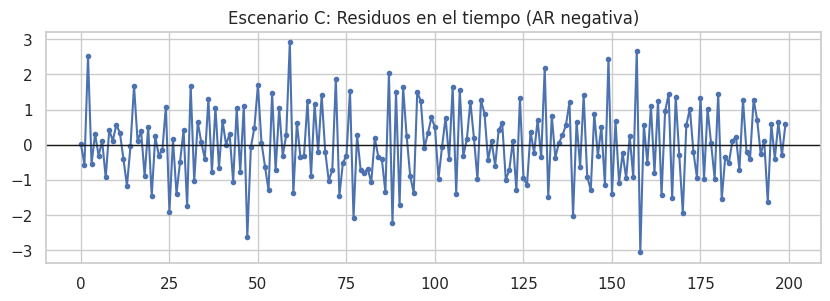

In [ ]:
# Residuos en el tiempo para autocorrelación negativa

plt.figure(figsize=(10,3))
plt.plot(df_C["t"], df_C["e_hat"], marker="o", ms=3, ls="-")
plt.axhline(0, color="k", lw=1)
plt.title("Escenario C: Residuos en el tiempo (AR negativa)")
plt.show()

In [ ]:
dw_C = durbin_watson(df_C["e_hat"])
print("Durbin-Watson:", round(dw_C, 4))

Durbin-Watson: 2.9863


Nuestro DW cercano a 3  es una señal clara de autocorrelación negativa. En el gráfico de residuos, esto se refleja como una oscilación constante donde un residuo positivo es seguido casi siempre por uno negativo y viceversa (forma de zigzag).

#Aprendizajes Obtenidos


Aprendimos que si ignoramos el "ruido" creciente o la conexión entre errores pasados y presentes, nuestras conclusiones sobre qué variables son importantes pueden ser erróneas, también aprendimos que si conocemos la causa del desorden en los datos, podemos usarla a nuestro favor para obtener el modelo más preciso posible y que si no podemos arreglar el modelo, al menos debemos "ajustar" nuestras reglas de medición para no mentir sobre la significancia de los resultados.

#Aplicaciones en otros ámbitos


En los mercados financieros, el riesgo casi nunca es constante pues los precios de las acciones suelen tener "clusters" de volatilidad pero si aplicamos correcciones como las del Escenario A, podemos calcular el Valor en Riesgo (VaR) de forma más precisa.
También donde podríamos aplicar esto es en el análisis de inflación ya que la inflación de hoy suele depender de la de ayer y si un banco central intenta predecir el impacto de la oferta monetaria sin corregir la autocorrelación, sus políticas podrían basarse en proyecciones que ignoran la persistencia de los choques económicos.

In [ ]:
from google.colab import files

# Genera el HTML sin el código gris
!jupyter nbconvert --to html --no-input "/content/drive/MyDrive/Colab Notebooks/Econometría 1/Tercera_evidencia_ofi.ipynb"

# Fuerza la descarga a tu computadora
files.download("/content/drive/MyDrive/Colab Notebooks/Econometría 1/Tercera_evidencia_ofi.html")

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Econometría 1/Tercera_evidencia_ofi.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 553089 bytes to /content/drive/MyDrive/Colab Notebooks/Econometría 1/Tercera_evidencia_ofi.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>